# Métricas y figuras de resultados — Sem1

Genera material para la sección de Resultados a partir de una corrida existente:
caracterización del corpus, histogramas de longitudes, curvas de pérdida,
comparación de METEOR / ROUGE-L F1 / BERTScore F1 y diagnósticos de generación.

**Ejecución local, sin entrenamiento, inferencia, descargas ni llamadas a APIs.**
Las métricas se agregan desde `per_prediction.csv` y se contrastan con los resúmenes
guardados. BERTScore no vuelve a calcularse. Los archivos originales se leen sin
modificarlos. Las salidas visibles y las tablas contienen únicamente agregados;
no se muestran cuerpos de noticias, afirmaciones individuales ni identificadores.

Instalación: `python -m pip install -e ".[analysis]"`. Ejecutar todas las celdas en orden.
Los datos y artefactos locales necesarios no están incluidos en Git.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import importlib.metadata
import json
import platform
import re
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from IPython import get_ipython

get_ipython().run_line_magic('matplotlib', 'inline')

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'configs/models.json').is_file() and (p / 'src').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Abre el notebook desde la raíz del repositorio o notebooks/.')

# Ajusta AMBAS rutas al analizar otra corrida y su corpus correspondiente.
RUN_ID = 'sem1_20261102_400_claims_controlled_5ep_v2'
REFERENCE_DIR = ROOT / 'artifacts/sem1_20261031/final'
RUN_DIR = ROOT / 'artifacts/runs' / RUN_ID
OUTPUT_DIR = RUN_DIR / 'evaluation/paper_results'
EXPECTED_SPLITS = {'train': 320, 'validation': 40, 'test': 40}
MODEL_IDS = ['t5s_spanish', 'barto_spanish', 'mbart50_es', 'umt5_base_es']
NAMES = dict(zip(MODEL_IDS, ['T5S', 'BARTO', 'mBART-50', 'uMT5-Base']))
COLORS = dict(zip(MODEL_IDS, ['#245572', '#228277', '#BA7737', '#855D93']))
METRICS = ['meteor', 'rouge_l_precision', 'rouge_l_recall', 'rouge_l_f1',
           'bertscore_precision', 'bertscore_recall', 'bertscore_f1']
PRIMARY = ['meteor', 'rouge_l_f1', 'bertscore_f1']
LABELS = {'meteor': 'METEOR', 'rouge_l_f1': 'ROUGE-L F1', 'bertscore_f1': 'BERTScore F1'}
sys.path.insert(0, str(ROOT / 'src'))
from claim_extraction.metrics import operational_diagnostics, tokenize

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titlesize': 12, 'axes.labelsize': 10,
                     'figure.dpi': 110, 'savefig.dpi': 300,
                     'pdf.fonttype': 42, 'ps.fonttype': 42})
input_hashes, generated_files, checks = {}, [], []

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

def track(path):
    if not path.is_file():
        raise FileNotFoundError(f'Falta el artefacto local: {path.relative_to(ROOT)}')
    input_hashes[str(path.relative_to(ROOT))] = sha256(path)
    return path

def require(condition, message):
    if not condition:
        raise ValueError(message)
    checks.append(message)

def save_table(frame, stem, index=False):
    frame = frame.reset_index() if index else frame
    for ext in ['csv', 'html']:
        path = OUTPUT_DIR / 'tables' / f'{stem}.{ext}'
        if ext == 'csv':
            frame.to_csv(path, index=False, encoding='utf-8-sig')
        else:
            frame.style.format(precision=4).hide(axis='index').to_html(path)
        generated_files.append(str(path.relative_to(OUTPUT_DIR)))
    display(frame.style.format(precision=4).hide(axis='index'))

def save_figure(fig, stem):
    for ext in ['png', 'pdf']:
        path = OUTPUT_DIR / 'figures' / f'{stem}.{ext}'
        fig.savefig(path, bbox_inches='tight', facecolor='white')
        generated_files.append(str(path.relative_to(OUTPUT_DIR)))
    plt.show()
    plt.close(fig)

print(f'Corrida: {RUN_ID}')

Corrida: sem1_20261102_400_claims_controlled_5ep_v2


## 1. Verificar corpus, prueba y métricas guardadas

Antes de exportar, se comprueban tamaños, referencias completas, separación de
identificadores y hashes, y correspondencia de las 40 predicciones de cada modelo
con el mismo test. Los promedios deben coincidir con los resúmenes ya evaluados.

In [2]:
splits = {name: pd.read_csv(track(REFERENCE_DIR / f'{name}.csv'),
                          dtype=str, keep_default_na=False)
          for name in EXPECTED_SPLITS}
for name, frame in splits.items():
    require(len(frame) == EXPECTED_SPLITS[name], f'Tamaño correcto: {name}.')
    require({'record_id', 'source_text', 'reference_claim', 'source_hash', 'claim_hash'} <= set(frame),
            f'Columnas de referencia disponibles: {name}.')
    for col in ['record_id', 'source_text', 'reference_claim', 'source_hash', 'claim_hash']:
        require(frame[col].str.strip().ne('').all(), f'Valores completos: {name}/{col}.')
    for col in ['record_id', 'source_hash', 'claim_hash']:
        require(frame[col].is_unique, f'Sin duplicados internos: {name}/{col}.')

for col in ['record_id', 'source_hash', 'claim_hash']:
    for a, b in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
        require(set(splits[a][col]).isdisjoint(splits[b][col]),
                f'Sin solapamiento exacto: {a}/{b}/{col}.')

test = splits['test'].set_index('record_id', verify_integrity=True)
details, summary_rows = {}, []
for model_id in MODEL_IDS:
    folder = RUN_DIR / 'evaluation' / model_id
    detail = pd.read_csv(track(folder / 'per_prediction.csv'),
                         dtype={'record_id': str}, keep_default_na=False)
    require({'record_id', 'model_id', 'reference_claim', 'source_hash', 'input_text', 'claim',
             'prediction_tokens', *METRICS} <= set(detail), f'Detalle completo: {model_id}.')
    require(detail['record_id'].is_unique and set(detail['record_id']) == set(test.index),
            f'Mismo test completo, sin duplicados: {model_id}.')
    require(detail['model_id'].eq(model_id).all(), f'Identidad correcta: {model_id}.')
    detail = detail.set_index('record_id').loc[test.index]
    require(detail['reference_claim'].eq(test['reference_claim']).all(),
            f'Referencias coincidentes: {model_id}.')
    require(detail['source_hash'].eq(test['source_hash']).all(),
            f'Fuentes coincidentes: {model_id}.')
    normalize_spaces = lambda value: ' '.join(str(value).split())
    require(detail['input_text'].map(normalize_spaces).eq(
                test['source_text'].map(normalize_spaces)).all(), f'Entradas coincidentes: {model_id}.')
    values = detail[METRICS].apply(pd.to_numeric, errors='raise')
    require(np.isfinite(values.to_numpy()).all(), f'Métricas finitas: {model_id}.')
    require(((values >= 0) & (values <= 1)).all().all(), f'Métricas en escala 0–1: {model_id}.')
    summary = pd.read_csv(track(folder / 'summary.csv')).iloc[0]
    require(int(summary['prediction_n']) == len(test) and int(summary['reference_n']) == len(test),
            f'Cobertura de referencias completa: {model_id}.')
    averages = values.mean()
    require(np.allclose(averages, summary[METRICS].astype(float), rtol=1e-8, atol=1e-10),
            f'Promedios coincidentes con summary.csv: {model_id}.')
    diagnostic = operational_diagnostics(detail[['claim']].to_dict('records'))
    diagnostic_map = {'empty_rate': 'empty_rate', 'shorter_than_5_tokens_rate': 'shorter_than_5_tokens_rate',
                      'duplicate_output_rate': 'duplicate_output_rate',
                      'mean_prediction_tokens': 'mean_prediction_tokens_operational'}
    require(all(np.isclose(diagnostic[key], float(summary[target]))
                for key, target in diagnostic_map.items()), f'Diagnósticos coincidentes: {model_id}.')
    lengths = detail['claim'].map(lambda text: len(tokenize(text)))
    require(np.array_equal(lengths, pd.to_numeric(detail['prediction_tokens'])),
            f'Longitudes de salidas coincidentes: {model_id}.')
    details[model_id] = values.assign(prediction_tokens=lengths.to_numpy())
    summary_rows.append({'model_id': model_id, 'Modelo': NAMES[model_id], 'N': len(test),
                         **averages.to_dict(), **diagnostic})

summaries = pd.DataFrame(summary_rows).set_index('model_id').loc[MODEL_IDS]
# Se conserva solo información numérica para las visualizaciones por caso.
del detail, values
print(f'Validaciones completadas: {len(checks)}; {len(test)} noticias por modelo.')
for subdir in ['figures', 'tables']:
    (OUTPUT_DIR / subdir).mkdir(parents=True, exist_ok=True)

Validaciones completadas: 87; 40 noticias por modelo.


/var/folders/f_/f_wm3g5j59gbfp5kbvdx136r0000gn/T/ipykernel_59414/3093098480.py:18: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  test = splits['test'].set_index('record_id', verify_integrity=True)


## 2. Caracterización del corpus e histogramas

Las longitudes siguientes son **palabras separadas por espacios del texto completo**,
antes del truncamiento de los modelos. No representan tokens de los tokenizadores
ni una medida del contenido efectivamente visible después del límite de 512 tokens.
Los histogramas describen las 400 noticias del corpus; no se usan para ajustar modelos.

Partición,Noticias,Porcentaje
Entrenamiento,320,80.0000
Validación,40,10.0000
Prueba,40,10.0000


Texto,N,Media,Desviación estándar,Mínimo,P25,Mediana,P75,Máximo
Noticia,400.0000,869.8100,581.5557,163.0000,520.0000,744.5000,1047.5000,5013.0000
Referencia,400.0000,20.6775,5.3615,7.0000,17.0000,20.0000,24.0000,46.0000


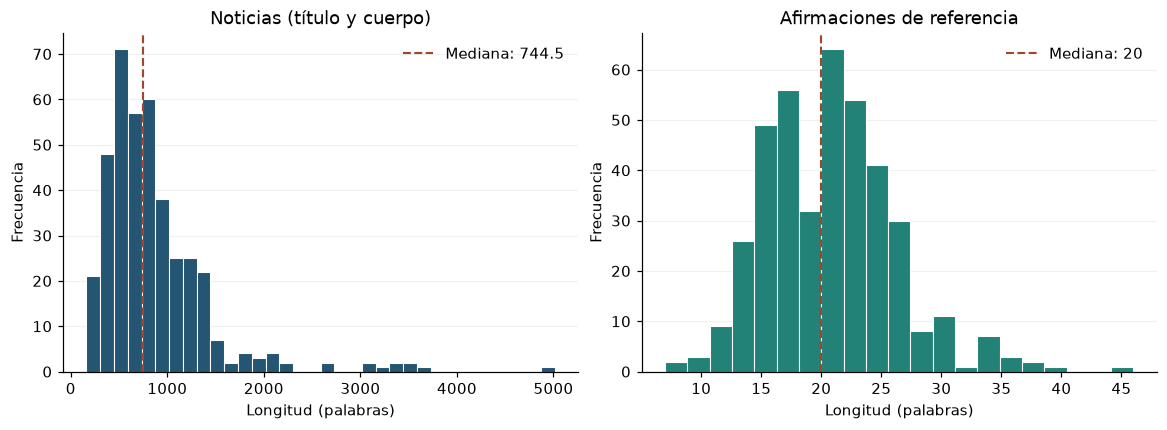

País/territorio (código de origen),Noticias
do,79
ve,61
mx,60
ar,57
ec,34
gt,20
uy,17
cu,15
pe,12
cl,9


In [3]:
corpus = pd.concat([frame.assign(split=name) for name, frame in splits.items()], ignore_index=True)
lengths = pd.DataFrame({'split': corpus['split'],
                       'Noticia': corpus['source_text'].map(lambda s: len(s.split())),
                       'Referencia': corpus['reference_claim'].map(lambda s: len(s.split()))})
split_table = pd.DataFrame([{'Partición': {'train': 'Entrenamiento', 'validation': 'Validación',
                                        'test': 'Prueba'}[name],
                             'Noticias': len(frame), 'Porcentaje': 100 * len(frame) / len(corpus)}
                            for name, frame in splits.items()])
save_table(split_table, '01_distribucion_particiones')
statistics = lengths[['Noticia', 'Referencia']].describe(
    percentiles=[.25, .5, .75]).T.reset_index(names='Texto')
statistics = statistics.rename(columns={'count': 'N', 'mean': 'Media', 'std': 'Desviación estándar',
    'min': 'Mínimo', '25%': 'P25', '50%': 'Mediana', '75%': 'P75', 'max': 'Máximo'})
save_table(statistics, '02_longitudes_palabras')

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), layout='constrained')
for ax, column, color in zip(axes, ['Noticia', 'Referencia'], ['#245572', '#228277']):
    data = lengths[column].to_numpy()
    bins = np.histogram_bin_edges(data, bins='fd')
    ax.hist(data, bins=bins, color=color, edgecolor='white', linewidth=.7)
    ax.axvline(np.median(data), color='#A1452B', linestyle='--', linewidth=1.4,
               label=f'Mediana: {np.median(data):g}')
    ax.set(title='Noticias (título y cuerpo)' if column == 'Noticia' else 'Afirmaciones de referencia',
           xlabel='Longitud (palabras)', ylabel='Frecuencia')
    ax.legend(frameon=False)
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=.18)
save_figure(fig, '01_histogramas_longitud_palabras')

if 'country' in corpus:
    countries = corpus['country'].replace('', 'Sin dato').value_counts().rename_axis(
        'País/territorio (código de origen)').reset_index(name='Noticias')
    save_table(countries, '03_distribucion_pais_territorio')

## 3. Pérdidas durante el ajuste supervisado

Se lee el `trainer_state.json` del checkpoint con el mayor paso numérico para
recuperar la historia completa, incluso si el checkpoint elegido fue anterior.
Cada panel muestra la evolución **dentro de un modelo**. Las pérdidas brutas
entre arquitecturas no se utilizan como ranking de calidad de las extracciones.

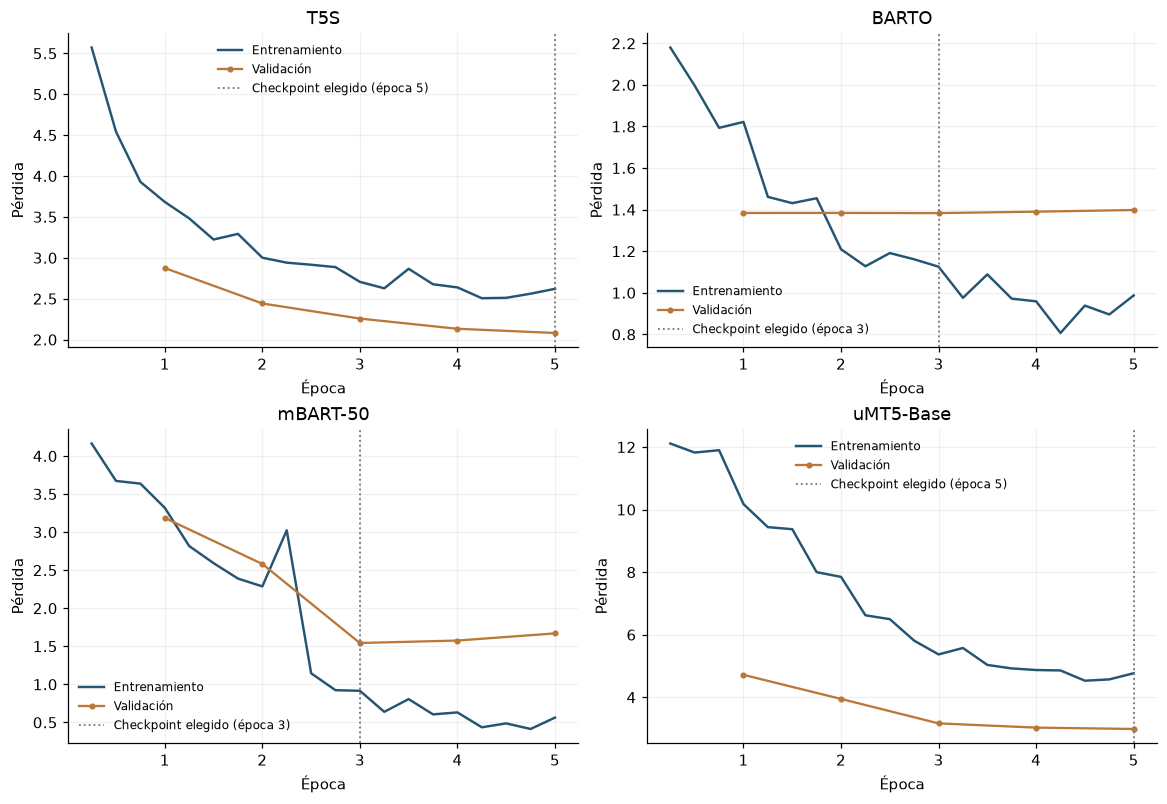

Modelo,Épocas ejecutadas,Época seleccionada,Pérdida de validación seleccionada,Checkpoint
T5S,5.0000,5.0000,2.0805,checkpoint-200
BARTO,5.0000,3.0000,1.3832,checkpoint-120
mBART-50,5.0000,3.0000,1.5431,checkpoint-120
uMT5-Base,5.0000,5.0000,2.9868,checkpoint-200


In [4]:
histories, training_rows = {}, []
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.2), layout='constrained')
for ax, model_id in zip(axes.flat, MODEL_IDS):
    model_dir = RUN_DIR / 'models' / model_id
    manifest = json.loads(track(model_dir / 'training_manifest.json').read_text())
    state_paths = list(model_dir.glob('checkpoint-*/trainer_state.json'))
    require(bool(state_paths), f'Historia de entrenamiento disponible: {model_id}.')
    state_path = max(state_paths, key=lambda p: int(p.parent.name.split('-')[-1]))
    state = json.loads(track(state_path).read_text())
    history = pd.DataFrame(state['log_history'])
    train_history = history.loc[history['loss'].notna(), ['epoch', 'loss']].copy()
    validation_history = history.loc[history['eval_loss'].notna(), ['epoch', 'step', 'eval_loss']].copy()
    require(not train_history.empty and not validation_history.empty,
            f'Curvas de entrenamiento y validación presentes: {model_id}.')
    best_step = int(Path(state['best_model_checkpoint']).name.split('-')[-1])
    best = validation_history.loc[validation_history['step'].eq(best_step)]
    require(len(best) == 1, f'Checkpoint elegido localizado en la historia: {model_id}.')
    best_epoch = float(best.iloc[0]['epoch'])
    training_rows.append({'Modelo': NAMES[model_id], 'Épocas ejecutadas': float(state['epoch']),
                          'Época seleccionada': best_epoch,
                          'Pérdida de validación seleccionada': float(best.iloc[0]['eval_loss']),
                          'Checkpoint': f'checkpoint-{best_step}'})
    histories[model_id] = {'train': train_history, 'validation': validation_history}
    ax.plot(train_history['epoch'], train_history['loss'], color='#245572',
            linewidth=1.6, label='Entrenamiento')
    ax.plot(validation_history['epoch'], validation_history['eval_loss'], color='#BA7737',
            marker='o', markersize=3, linewidth=1.5, label='Validación')
    ax.axvline(best_epoch, color='#777777', linestyle=':', linewidth=1.2,
               label=f'Checkpoint elegido (época {best_epoch:g})')
    ax.set(title=NAMES[model_id], xlabel='Época', ylabel='Pérdida')
    ax.grid(alpha=.18)
    ax.legend(frameon=False, fontsize=8)
save_figure(fig, '02_curvas_perdida_entrenamiento_validacion')
save_table(pd.DataFrame(training_rows), '04_checkpoints_seleccionados')

## 4. Métricas comparativas sobre el mismo test

Se exportan las medias por ejemplo de las métricas ya calculadas para los mismos
40 casos por modelo. METEOR es la métrica principal; ROUGE-L F1 y BERTScore F1
son complementarias. Los gráficos usan escala 0–1 y no representan porcentajes
de exactitud médica. El desglose P/R/F1 se conserva en una tabla complementaria.

Modelo,N,METEOR,ROUGE-L F1,BERTScore F1
T5S,40,0.1735,0.2209,0.8246
BARTO,40,0.3150,0.3258,0.8997
mBART-50,40,0.2786,0.2941,0.8974
uMT5-Base,40,0.2160,0.1981,0.7427


Modelo,ROUGE-L Precisión,ROUGE-L Recall,ROUGE-L F1,BERTScore Precisión,BERTScore Recall,BERTScore F1
T5S,0.3560,0.1857,0.2209,0.8412,0.8094,0.8246
BARTO,0.3516,0.3167,0.3258,0.9034,0.8961,0.8997
mBART-50,0.3256,0.2885,0.2941,0.8998,0.8952,0.8974
uMT5-Base,0.1874,0.2328,0.1981,0.7464,0.7392,0.7427


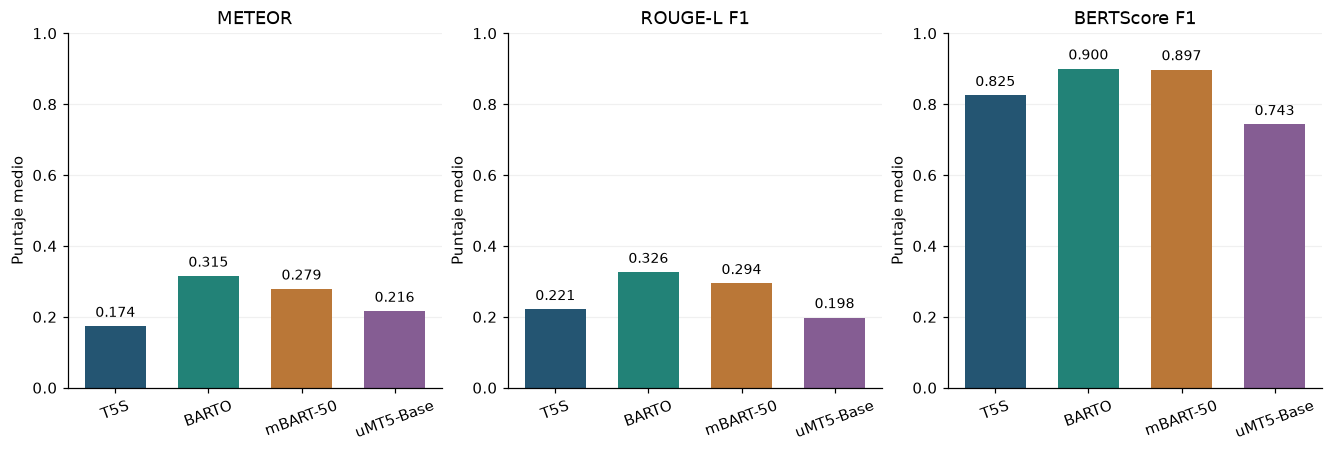

In [5]:
main_table = summaries[['Modelo', 'N', *PRIMARY]].rename(columns=LABELS).reset_index(drop=True)
save_table(main_table, '05_metricas_principales')
prf_columns = [column for column in METRICS if column != 'meteor']
prf_labels = {f'{prefix}_{suffix}': f'{name} {label}'
              for prefix, name in [('rouge_l', 'ROUGE-L'), ('bertscore', 'BERTScore')]
              for suffix, label in [('precision', 'Precisión'), ('recall', 'Recall'), ('f1', 'F1')]}
save_table(summaries[['Modelo', *prf_columns]].rename(columns=prf_labels).reset_index(drop=True),
           '06_desglose_precision_recall_f1')

fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout='constrained')
for ax, metric in zip(axes, PRIMARY):
    values = summaries[metric].to_numpy()
    bars = ax.bar(list(NAMES.values()), values, color=list(COLORS.values()), width=.65)
    ax.bar_label(bars, labels=[f'{value:.3f}' for value in values], padding=4, fontsize=9)
    ax.set(title=LABELS[metric], ylabel='Puntaje medio', ylim=(0, 1))
    ax.tick_params(axis='x', labelrotation=20)
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=.18)
save_figure(fig, '03_comparacion_metricas')

## 5. Distribución de puntajes y diagnósticos de generación

Los diagramas de caja muestran la mediana, los cuartiles, bigotes de 1,5 veces
el rango intercuartílico y valores fuera de ellos. Describen variación entre
noticias; no son intervalos de confianza ni pruebas de significancia.
Los diagnósticos operativos se calculan con la misma función del evaluador.

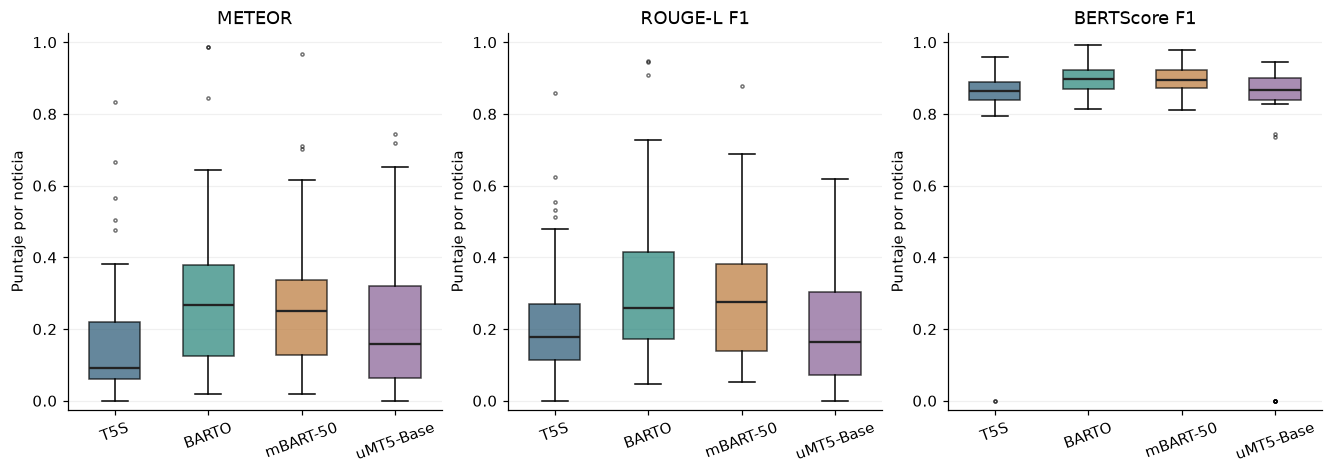

Modelo,Salidas vacías (%),Menos de 5 tokens (%),Longitud media (tokens léxicos),Repeticiones adicionales (%)
T5S,2.5000,22.5000,12.8500,5.0000
BARTO,0.0000,0.0000,18.8500,0.0000
mBART-50,0.0000,0.0000,18.6500,0.0000
uMT5-Base,15.0000,20.0000,20.7250,0.0000


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), layout='constrained')
for ax, metric in zip(axes, PRIMARY):
    boxes = ax.boxplot([details[model_id][metric].to_numpy() for model_id in MODEL_IDS],
                       tick_labels=list(NAMES.values()), patch_artist=True, widths=.55,
                       medianprops={'color': '#222222', 'linewidth': 1.5},
                       flierprops={'marker': '.', 'markersize': 4, 'alpha': .55})
    for patch, color in zip(boxes['boxes'], COLORS.values()):
        patch.set_facecolor(color)
        patch.set_alpha(.70)
    ax.set(title=LABELS[metric], ylabel='Puntaje por noticia', ylim=(-.025, 1.025))
    ax.tick_params(axis='x', labelrotation=20)
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=.18)
save_figure(fig, '04_distribucion_metricas_por_noticia')

diagnostic_table = summaries[['Modelo', 'empty_rate', 'shorter_than_5_tokens_rate',
                             'mean_prediction_tokens', 'duplicate_output_rate']].copy()
rates = ['empty_rate', 'shorter_than_5_tokens_rate', 'duplicate_output_rate']
diagnostic_table[rates] = diagnostic_table[rates] * 100
diagnostic_table = diagnostic_table.rename(columns={
    'empty_rate': 'Salidas vacías (%)', 'shorter_than_5_tokens_rate': 'Menos de 5 tokens (%)',
    'mean_prediction_tokens': 'Longitud media (tokens léxicos)',
    'duplicate_output_rate': 'Repeticiones adicionales (%)'})
save_table(diagnostic_table.reset_index(drop=True), '07_diagnosticos_generacion')

## 6. Procedencia y archivos exportados

Los archivos se guardan en `artifacts/runs/<RUN_ID>/evaluation/paper_results/`.
PNG se exporta a 300 dpi y PDF conserva los elementos vectoriales. Las tablas
se exportan a CSV y HTML; su numeración interna no fija la numeración del artículo.

Para la sección de Resultados: histograma → caracterización; curvas → ajuste;
tabla principal → comparación; diagnósticos → características de las salidas.
Las causas de diferencias y comparación con otros estudios corresponden a Discusión.
Los ejemplos textuales y la revisión de errores semánticos requieren una revisión
separada; este notebook no los presenta como evaluación humana realizada.

In [7]:
for relative, expected_hash in input_hashes.items():
    require(sha256(ROOT / relative) == expected_hash, f'Entrada conservada: {relative}.')

manifest = {
    'run_id': RUN_ID, 'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'reference_directory': str(REFERENCE_DIR.relative_to(ROOT)),
    'split_counts': {name: len(frame) for name, frame in splits.items()},
    'models': MODEL_IDS, 'test_cases_per_model': len(test),
    'inputs_sha256': input_hashes, 'validation_checks_passed': len(checks),
    'versions': {'python': platform.python_version(),
                 **{name: importlib.metadata.version(name)
                    for name in ['pandas', 'numpy', 'matplotlib']}},
    'files': {relative: sha256(OUTPUT_DIR / relative) for relative in generated_files},
    'metric_source': 'Medias de per_prediction.csv, contrastadas con summary.csv; sin recalcular modelos.',
    'histogram_unit': 'Palabras separadas por espacios del texto completo, antes del truncamiento.',
    'loss_history': 'Último checkpoint por paso numérico; seleccionado indicado por modelo.'
}
(OUTPUT_DIR / 'manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2) + '\n')
display(pd.DataFrame({'Archivo': [*generated_files, 'manifest.json']}))
print(f'Listo: {len(generated_files)} archivos y manifiesto; {len(checks)} comprobaciones superadas.')
print(f'Destino: {OUTPUT_DIR.relative_to(ROOT)}')

,Archivo
0,tables/01_distribucion_particiones.csv
1,tables/01_distribucion_particiones.html
2,tables/02_longitudes_palabras.csv
3,tables/02_longitudes_palabras.html
4,figures/01_histogramas_longitud_palabras.png
5,figures/01_histogramas_longitud_palabras.pdf
6,tables/03_distribucion_pais_territorio.csv
7,tables/03_distribucion_pais_territorio.html
8,figures/02_curvas_perdida_entrenamiento_valida...
9,figures/02_curvas_perdida_entrenamiento_valida...


Listo: 22 archivos y manifiesto; 118 comprobaciones superadas.
Destino: artifacts/runs/sem1_20261102_400_claims_controlled_5ep_v2/evaluation/paper_results
